<center><h1>Tang_Xiaoyun_HW4</h1></center>
<br>
<br>

Name: Xiaoyun Tang
<br>
Github Username: Nokiovo099
<br>
USC ID: 3843547131

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

Part 1 was my Homework 3. The homework says we don't need to hand in Part 1 again, so here I only kept the parts that Homework 4 needs: loading the data, splitting it into train and test, and making the features. My answers to 1(c)i (list of features) and 1(c)iii (bootstrap) are in Homework 3.

### (a) Obtain Data

Import packages

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.model_selection import StratifiedKFold
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score)
from sklearn.exceptions import ConvergenceWarning

pd.set_option("display.max_columns", None)

# Our classes are (almost) linearly separable, so an un-penalized logistic regression
# never fully converges. We stop it early on purpose (max_iter), so we hide this warning.
warnings.filterwarnings("ignore", category=ConvergenceWarning)
# New scikit-learn versions (1.8+) warn that the 'penalty' argument will change in the future.
# penalty="l1" still works in those versions, so we hide these two warnings.
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="Inconsistent values")

Get the AReM Data Set

I downloaded the AReM data and put it in the data/AReM folder. It has 7 folders (one for each activity) and 88 files in total. Each file has a time column and 6 time series.

When I opened the files, I saw that a few of them need a little cleaning:
- Lines that start with # are notes, not data, so I skip them.
- bending2/dataset4.csv uses spaces instead of commas, and cycling/dataset9.csv and cycling/dataset14.csv have an extra comma at the end of one line. To fix both problems at once, I change every comma into a space and then split the line by spaces.
- sitting/dataset8.csv has 479 rows instead of 480, so one row is missing. I keep the 479 rows and don't make up the missing one. The missing value is unknown, but since it is only 1 of 480 values, I think the effect on the features is likely small.

In [2]:
# find the data folder with a relative path
# Jupyter usually runs the notebook from the notebook/ folder, so we try "../data/AReM" first.
# Some editors (for example VS Code) may run it from another folder,
# so we also look a few folders down from the current folder.
import glob

data_dir = None
for path in ["../data/AReM", "data/AReM", "*/data/AReM", "*/*/data/AReM", "*/*/*/data/AReM"]:
    found = glob.glob(path)
    if len(found) > 0:
        data_dir = found[0]
        break

if data_dir is None:
    raise FileNotFoundError("Cannot find the data/AReM folder. Please keep the folder structure of the repo.")
print("Data folder:", data_dir)

column_names = ["time", "avg_rss12", "var_rss12", "avg_rss13",
                "var_rss13", "avg_rss23", "var_rss23"]


def load_file(file_path):
    rows = []
    with open(file_path) as f:
        for line in f:
            line = line.strip()
            # skip empty lines and the header lines that start with #
            if line == "" or line.startswith("#"):
                continue
            # some files use spaces and some have an extra comma at the end,
            # so just turn commas into spaces and split
            line = line.replace(",", " ")
            rows.append([float(x) for x in line.split()])
    return pd.DataFrame(rows, columns=column_names)


activities = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]

total = 0
for activity in activities:
    files = [f for f in os.listdir(os.path.join(data_dir, activity)) if f.endswith(".csv")]
    print(activity, ":", len(files), "files")
    total += len(files)
print("Total:", total, "files")

Data folder: ../data/AReM
bending1 : 7 files
bending2 : 6 files
cycling : 15 files
lying : 15 files
sitting : 15 files
standing : 15 files
walking : 15 files
Total: 88 files


**Result:** I get 7 folders and 88 files, which matches the 88 instances in the dataset description. The two bending folders have fewer files (7 and 6) than the other five folders (15 each).

### (b) Splitting Data

The homework tells us how to split the data:
- In bending1 and bending2: datasets 1 and 2 are **test** data.
- In the other folders: datasets 1, 2 and 3 are **test** data.
- Everything else is **train** data.

In [3]:
split_rows = []
for activity in activities:
    files = [f for f in os.listdir(os.path.join(data_dir, activity)) if f.endswith(".csv")]
    for f in files:
        number = int(f.replace("dataset", "").replace(".csv", ""))
        # bending folders: dataset 1-2 are test, other folders: dataset 1-3
        if activity == "bending1" or activity == "bending2":
            test_limit = 2
        else:
            test_limit = 3
        if number <= test_limit:
            split = "test"
        else:
            split = "train"
        split_rows.append([activity, number, f, split])

split_table = pd.DataFrame(split_rows, columns=["activity", "number", "dataset", "split"])
split_table = split_table.sort_values(["activity", "number"]).reset_index(drop=True)

print("Number of train instances:", (split_table["split"] == "train").sum())
print("Number of test instances:", (split_table["split"] == "test").sum())

Number of train instances: 69
Number of test instances: 19


**Result:** I get 69 instances for training and 19 for testing (2 + 2 from the two bending folders, and 3 × 5 = 15 from the other five folders). 69 + 19 = 88, so every file is used exactly once.

### (c) Feature Extraction

For every instance (one csv file), I find 7 numbers for each of the 6 time series: min, max, mean, median, standard deviation, 1st quartile and 3rd quartile. That gives 6 × 7 = 42 features for each instance. Here I just keep these numbers as they are. (Later, in Part 2, I standardize them inside cross-validation for logistic regression, but I use them as they are for naive Bayes.)

Note: pandas .std() divides by n − 1, not by n. This is the "sample" standard deviation.

**What I changed for Homework 4:** Homework 4 asks us to cut each time series into l pieces and find the 7 features for every piece. So I turned my Homework 3 code into a function, **extract_features(data_list, l)**.
- np.array_split cuts a time series into l pieces. 480 can't always be divided evenly by l, so some pieces may have one more value than others.
- When l = 1, nothing is cut, so I get the same table as in Homework 3.
- When l is bigger, the name tells which piece a feature comes from. For example, min1_part2 means the min of the 2nd piece of time series 1.
- **load_instances** reads each file only once. Homework 4 makes the features many times (for l = 1 to 20), so this saves time.

In [4]:
def load_instances(table):
    # read every file in the table once, so we don't read the same file again for each l
    data_list = []
    for i in range(len(table)):
        activity = table.loc[i, "activity"]
        file_name = table.loc[i, "dataset"]
        data_list.append(load_file(os.path.join(data_dir, activity, file_name)))
    return data_list


def extract_features(data_list, l):
    feature_rows = []
    for df in data_list:
        row = {}
        for k in range(1, 7):     # 6 time series
            chunks = np.array_split(df[column_names[k]].values, l)
            for j in range(l):
                series = pd.Series(chunks[j])
                if l == 1:
                    tag = str(k)
                else:
                    tag = str(k) + "_part" + str(j + 1)
                row["min" + tag] = series.min()
                row["max" + tag] = series.max()
                row["mean" + tag] = series.mean()
                row["median" + tag] = series.median()
                row["std" + tag] = series.std()
                row["1st_quart" + tag] = series.quantile(0.25)
                row["3rd_quart" + tag] = series.quantile(0.75)
        feature_rows.append(row)
    return pd.DataFrame(feature_rows)


features = extract_features(load_instances(split_table), 1)
features.index = range(1, 89)     # instance number starts from 1
features.index.name = "Instance"

print(features.shape)
features.round(3)

(88, 42)


,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,median2,std2,1st_quart2,3rd_quart2,min3,max3,mean3,median3,std3,1st_quart3,3rd_quart3,min4,max4,mean4,median4,std4,1st_quart4,3rd_quart4,min5,max5,mean5,median5,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
Instance,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,37.25,45.00,40.625,40.50,1.477,39.25,42.000,0.0,1.30,0.359,0.430,0.323,0.00,0.500,4.00,29.50,19.041,19.250,4.463,16.00,23.250,0.0,7.23,0.833,0.50,0.966,0.000,1.120,27.25,38.25,34.311,35.00,2.188,33.000,36.00,0.00,1.92,0.571,0.43,0.583,0.000,1.300
2,38.00,45.67,42.813,42.50,1.436,42.00,43.670,0.0,1.22,0.372,0.470,0.289,0.00,0.500,2.00,29.50,20.097,21.000,3.894,19.00,22.250,0.0,5.76,0.876,0.50,1.047,0.000,1.145,27.67,38.50,33.025,33.00,1.995,32.000,34.50,0.00,3.11,0.571,0.43,0.601,0.000,1.300
3,35.00,47.40,43.954,44.33,1.559,43.00,45.000,0.0,1.70,0.426,0.470,0.339,0.00,0.500,6.50,29.75,22.122,23.000,3.031,19.75,24.000,0.0,4.44,0.497,0.43,0.551,0.000,0.830,29.00,38.50,35.588,36.00,2.000,35.362,36.50,0.00,1.79,0.493,0.43,0.514,0.000,0.940
4,33.00,47.75,42.180,43.50,3.671,39.15,45.000,0.0,3.00,0.696,0.500,0.631,0.00,1.120,8.50,30.00,22.184,23.000,3.810,20.50,24.372,0.0,5.15,0.990,0.83,0.954,0.430,1.300,20.00,38.67,33.494,35.00,3.849,30.458,36.33,0.00,2.18,0.614,0.50,0.524,0.000,1.000
5,33.00,45.75,41.678,41.75,2.243,41.33,42.750,0.0,2.83,0.536,0.500,0.405,0.43,0.710,3.00,28.25,19.007,19.125,4.087,16.50,22.062,0.0,6.42,0.842,0.50,0.929,0.430,1.120,23.67,37.50,29.857,30.00,2.411,28.458,31.25,0.00,1.79,0.383,0.43,0.389,0.000,0.500
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,19.50,45.33,33.587,34.25,4.651,30.25,37.000,0.0,14.67,4.577,4.260,2.461,2.87,6.105,7.33,23.25,15.318,15.330,2.970,13.25,17.270,0.0,9.00,3.227,3.10,1.647,2.050,4.260,6.33,25.00,15.892,16.00,3.284,13.730,18.25,0.00,8.32,3.260,3.11,1.640,2.050,4.322
85,19.75,45.50,34.323,35.25,4.752,31.00,38.000,0.0,13.47,4.456,3.900,2.599,2.49,5.970,6.25,22.25,15.210,15.250,2.711,13.50,17.000,0.0,9.00,3.277,3.11,1.500,2.170,4.390,6.25,23.25,15.550,15.75,3.120,13.500,17.75,0.00,9.67,3.433,3.20,1.733,2.157,4.565
86,19.50,46.00,34.546,35.25,4.842,31.25,37.812,0.0,12.47,4.372,4.135,2.360,2.49,5.800,7.00,22.67,15.186,15.250,2.758,13.25,17.000,0.0,8.34,3.029,2.86,1.665,1.790,4.110,7.00,22.75,15.760,15.75,2.823,14.000,17.75,0.00,10.00,3.338,3.08,1.657,2.160,4.335


**Result:** I get 88 rows (one for each instance) and 42 columns (7 features × 6 time series), with the same names as in the homework (min1, max1, ..., 1st_quart6, 3rd_quart6). Instances 1–7 are bending1, 8–13 are bending2, 14–28 are cycling, 29–43 are lying, 44–58 are sitting, 59–73 are standing and 74–88 are walking.

**Duplicate files:** In Homework 3, I noticed that some rows in this table had exactly the same numbers, so I compared the raw files. I found:
- These pairs of files are **exact copies**: cycling dataset1 and dataset15 (instances 14 and 28), lying dataset1 and dataset15 (29 and 43), lying 3 and 11 (31 and 39), lying 5 and 12 (33 and 40), lying 7 and 13 (35 and 41), lying 9 and 14 (37 and 42).
- lying dataset10 (instance 38) is **almost a copy** of lying dataset1: only 1 of the 480 rows is different.

The homework says to use all 88 instances, so I kept them all. But this matters for Homework 4: three test files (cycling dataset1, lying dataset1 and lying dataset3) have an exact copy in the training set. So the test results for cycling and lying may look a bit better than they really are.

**1(c)iv. Select features:** I chose **min, mean and max** (one of the options the homework gives).

- **Mean** tells the usual level of the signal, and this can be different for different activities.
- **Min** and **max** tell how low and how high the signal goes. For example, moving activities like walking can go much lower than still ones like sitting.
- Median and the quartiles also describe the middle of the data, so I think they mostly repeat what the mean already tells us. Min and max add new information about the edges of the data.

This choice is based on what the features mean. In Part 2, the models (RFE and L1) also check which features really help.

In the next cell I split the files into train and test, read each file once, and make the labels. For the binary problem, 1 = bending (bending1 or bending2) and 0 = any other activity.

In [5]:
SELECTED_FEATURES = ["min", "mean", "max"]

train_table = split_table[split_table["split"] == "train"].reset_index(drop=True)
test_table = split_table[split_table["split"] == "test"].reset_index(drop=True)
train_data = load_instances(train_table)
test_data = load_instances(test_table)

train_activity = train_table["activity"].values
test_activity = test_table["activity"].values
y_train = np.isin(train_activity, ["bending1", "bending2"]).astype(int)   # 1 = bending
y_test = np.isin(test_activity, ["bending1", "bending2"]).astype(int)
print("Train: bending =", y_train.sum(), " other =", (y_train == 0).sum())
print("Test:  bending =", y_test.sum(), " other =", (y_test == 0).sum())

Train: bending = 9  other = 60
Test:  bending = 4  other = 15


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

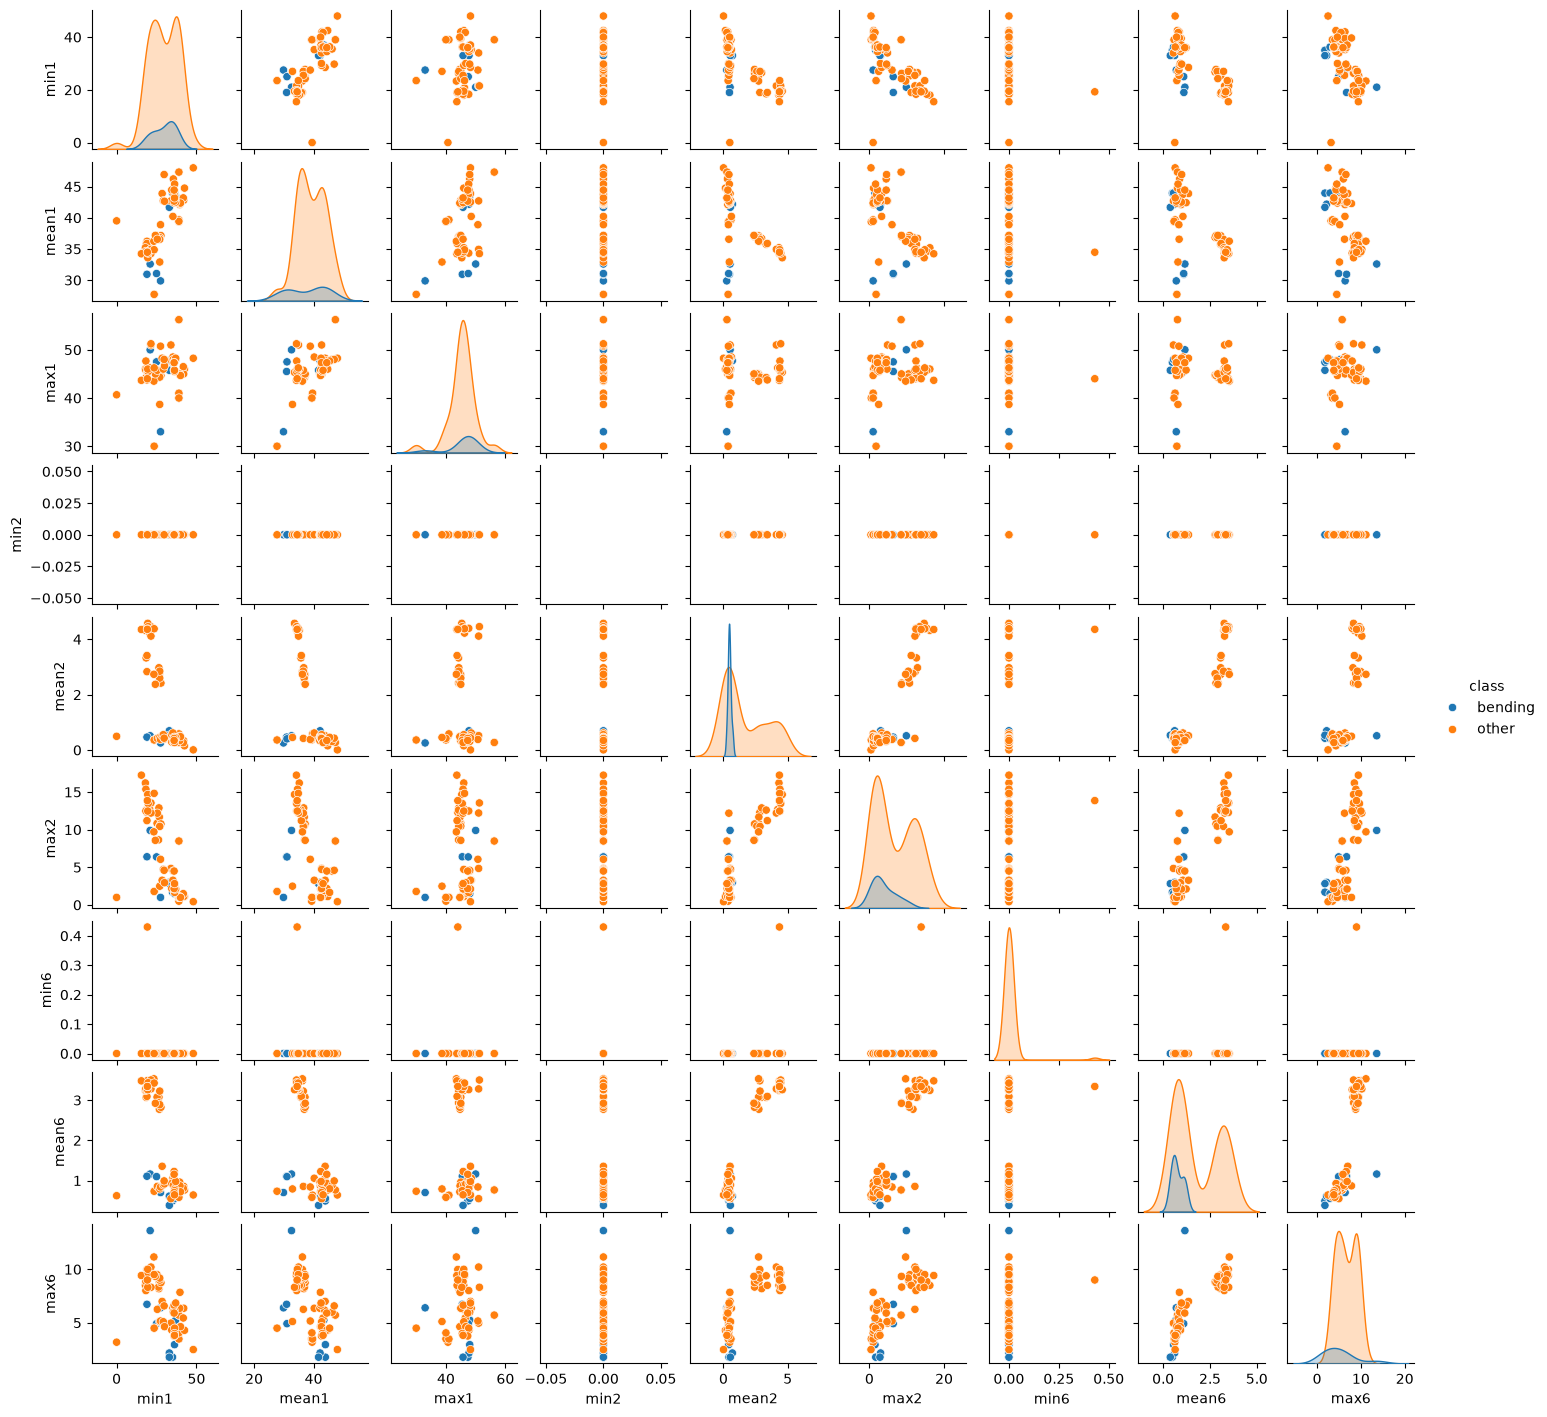

In [6]:
train_l1 = extract_features(train_data, 1)
plot_cols = [f + str(s) for s in [1, 2, 6] for f in SELECTED_FEATURES]
plot_df = train_l1[plot_cols].copy()
plot_df["class"] = np.where(y_train == 1, "bending", "other")

sns.pairplot(plot_df, vars=plot_cols, hue="class", height=1.6)
plt.show()

I drew a scatterplot matrix colored by class. Each small plot shows two features against each other. Blue = bending, orange = other. The plots on the diagonal show how one feature is spread out in each class.

What I see:
- min2 is 0 for all 69 training instances, and min6 is 0 for 68 of them. So these two features almost never change and can't really help.
- The bending points stay in a small area: mean2 is only about 0.26–0.70 and mean6 is about 0.38–1.16.
- Cycling and walking (the moving activities) have much bigger mean2 and mean6, so they are easy to tell apart from bending.
- But lying, sitting and standing also have small mean2 and mean6, so their points sit right on top of the bending points (36 of the 60 "other" points are in this area). So no single pair of features can separate bending from the others perfectly. We need to use several features together.

#### ii. Splitted Plots

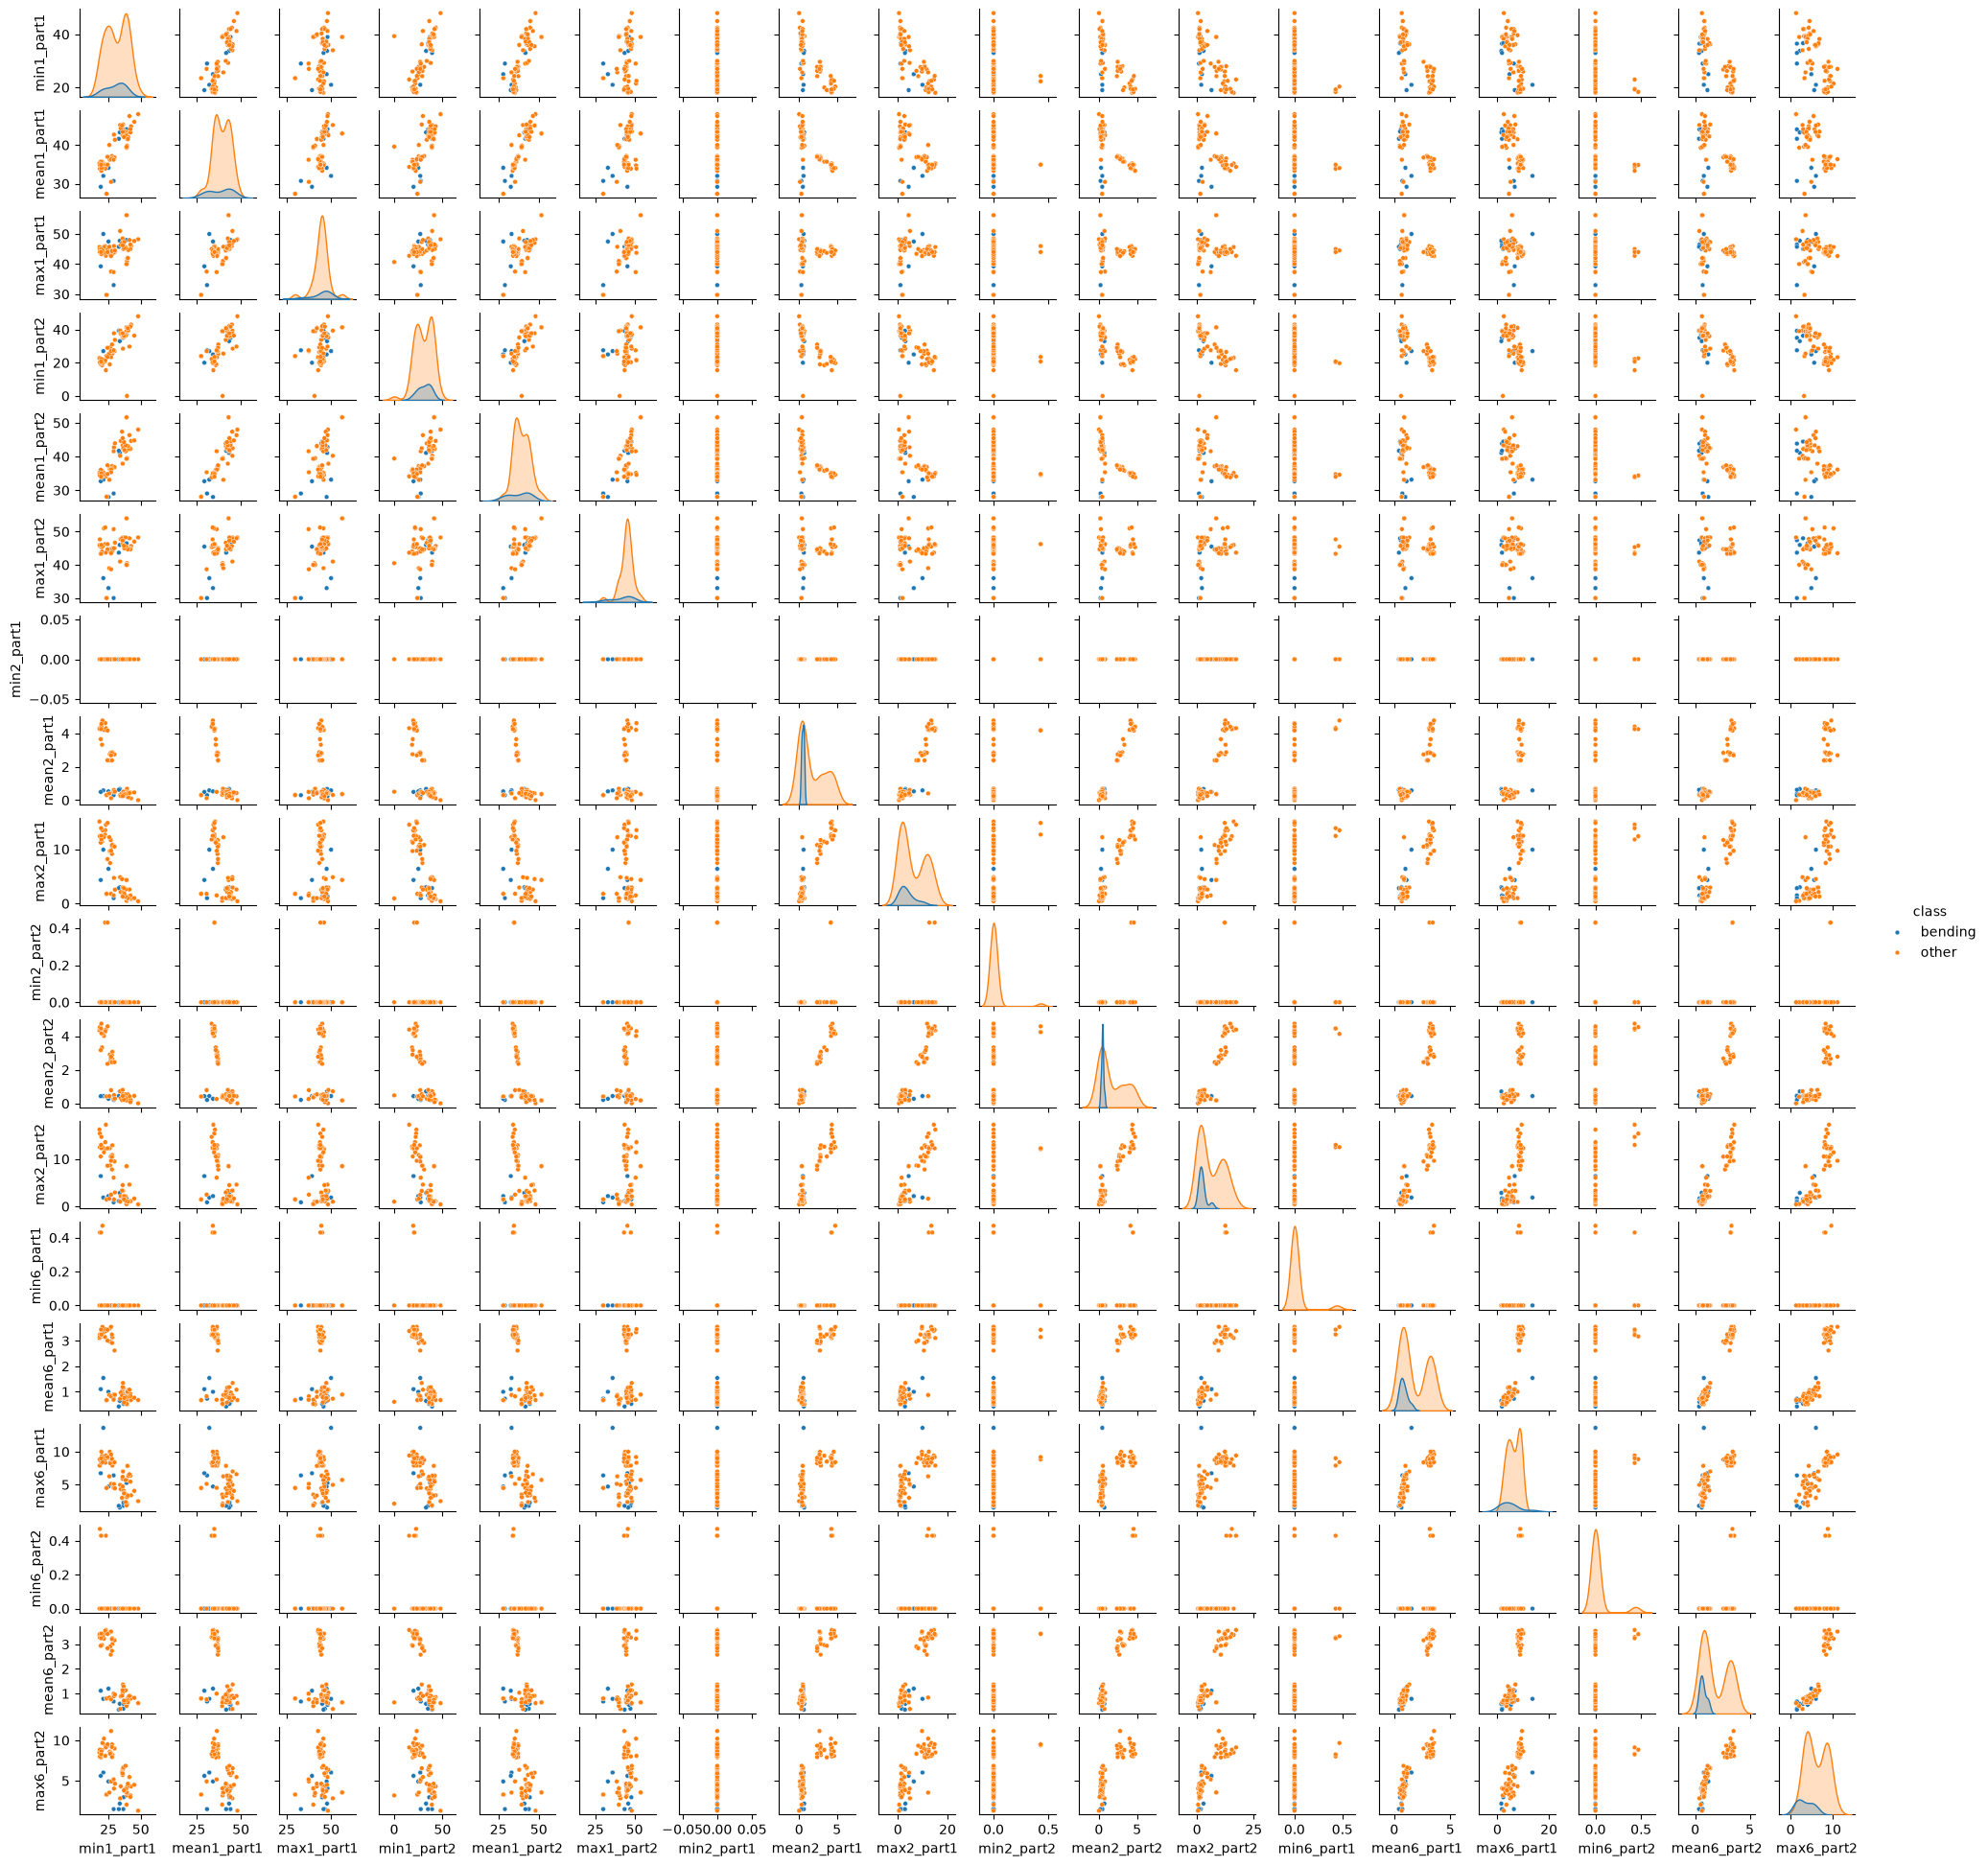

In [7]:
train_l2 = extract_features(train_data, 2)
plot_cols2 = [f + f"{s}_part{k}" for s in [1, 2, 6] for k in [1, 2] for f in SELECTED_FEATURES]
plot_df2 = train_l2[plot_cols2].copy()
plot_df2["class"] = np.where(y_train == 1, "bending", "other")

sns.pairplot(plot_df2, vars=plot_cols2, hue="class", height=1.1, plot_kws={"s": 12})
plt.show()

Now I cut each time series into 2 halves, so I get 18 features (min, mean and max of time series 1, 2 and 6, for part 1 and for part 2).

**Is there a big difference from 2(a)i?** Not really. The plots for part 1 and part 2 look almost the same as the plots for the whole series:
- bending is still in the area with small mean2 and mean6,
- min2 and min6 are still almost always 0,
- lying, sitting and standing still overlap with bending.

I think this makes sense: a person does the same activity for the whole 2 minutes, so the first half looks like the second half. The plots of part 1 vs. part 2 of the same feature show this too: for example, mean2_part1 and mean2_part2 are almost on a straight line (their correlation is about 0.99). So cutting the series gives us more features, but not much new information.

#### iii. Time Series Segments

**How I set it up:**
- **Logistic regression without a penalty:** sklearn adds an L2 penalty by default, so I set a very large budget, C = 1e10, to basically turn it off.
- **Feature selection with RFE:** the homework lets us use RFE (Recursive Feature Elimination) instead of p-values. RFE fits the model, throws away the feature with the smallest coefficient (in absolute value), and repeats. I standardize the features first, so that the coefficients can be compared fairly.
- **5-fold cross-validation:** I train on 4 folds, test on the 5th, do this 5 times, and average the accuracy.
- **Stratified cross-validation:** only 9 of the 69 training instances are bending. With normal random folds, some folds could get almost no bending instances. StratifiedKFold keeps about the same share of bending in every fold.
- **max_iter = 100:** the classes are almost separable, so the solver keeps making the coefficients bigger and bigger. I stop it early on purpose.

**Right way vs. wrong way to do cross-validation:**
- *Wrong way:* use all 69 training instances to pick the best p features first, and only then do cross-validation on the logistic regression. The feature selection has already "seen" the answers of the validation folds, so the CV accuracy looks better than it really is.
- *Right way:* every step that uses the labels has to happen inside each fold. In each fold I (1) fit the scaler on the 4 training folds only, (2) run RFE on the 4 training folds only, (3) fit logistic regression on the chosen features, and (4) test it on the fold that was left out. The left-out fold is never used to choose anything. My code does it the right way.

**How my search works:** For each l from 1 to 20, I make the features again (there are 6 × 7 × l of them). In each fold, RFE removes features one by one until only 1 is left. The order in which features are removed doesn't depend on p, so I run RFE only once and then take the top p features for every p. I try p = 1 to 20, to keep the search manageable and to favor smaller models. I did not test larger values of p. I use the same 5 folds for every l, so the comparison is fair. If two (l, p) pairs tie, I pick the simpler model (smaller l first, then smaller p).

In [8]:
# Same 5 stratified folds for every l, so all models are compared fairly.
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
binary_folds = list(skf.split(np.zeros(len(y_train)), y_train))

MAX_P = 20        # largest number of features we let RFE keep
BIG_C = 1e10      # huge budget C = (almost) no L2 penalty


def plain_logistic():
    return LogisticRegression(C=BIG_C, max_iter=100)


rfe_rows = []
for l in range(1, 21):
    X = extract_features(train_data, l).values
    correct = np.zeros(MAX_P)
    for train_idx, val_idx in binary_folds:
        # Everything that looks at labels (scaling + feature selection) is done
        # on the training part of the fold only. This is the "right way".
        scaler = StandardScaler().fit(X[train_idx])
        X_tr = scaler.transform(X[train_idx])
        X_val = scaler.transform(X[val_idx])
        y_tr, y_val = y_train[train_idx], y_train[val_idx]

        # RFE removes one feature at a time. The removal order does not depend on p,
        # so we run it once down to 1 feature and read the top p features from ranking_.
        rfe = RFE(plain_logistic(), n_features_to_select=1, step=1).fit(X_tr, y_tr)
        order = np.argsort(rfe.ranking_)

        for p in range(1, MAX_P + 1):
            cols = order[:p]
            model = plain_logistic().fit(X_tr[:, cols], y_tr)
            correct[p - 1] += np.sum(model.predict(X_val[:, cols]) == y_val)
    for p in range(1, MAX_P + 1):
        rfe_rows.append({"l": l, "p": p, "cv_accuracy": correct[p - 1] / len(y_train)})

rfe_results = pd.DataFrame(rfe_rows)
# Highest accuracy first; if tied, prefer the simpler model (smaller l, then smaller p).
rfe_results = rfe_results.sort_values(["cv_accuracy", "l", "p"], ascending=[False, True, True])
print(rfe_results.head(10).to_string(index=False))

best_l = int(rfe_results.iloc[0]["l"])
best_p = int(rfe_results.iloc[0]["p"])
best_cv_acc = rfe_results.iloc[0]["cv_accuracy"]
print("\nBest (l, p) =", (best_l, best_p), " CV accuracy =", round(best_cv_acc, 4))

 l  p  cv_accuracy
 1 12     0.985507
 2  5     0.985507
 1  3     0.971014
 1  6     0.971014
 1 11     0.971014
 1 13     0.971014
 1 14     0.971014
 1 15     0.971014
 1 16     0.971014
 1 17     0.971014

Best (l, p) = (1, 12)  CV accuracy = 0.9855


The best pair is **(l, p) = (1, 12)**, with 5-fold CV accuracy 0.9855 (68 of the 69 training instances are classified correctly). The pair (2, 5) has the same accuracy, but by my tie rule I keep the smaller l. So I don't need to cut the time series at all (l = 1).

In [9]:
# Refit on the whole training set with the best (l, p)
train_best = extract_features(train_data, best_l)
test_best = extract_features(test_data, best_l)

scaler_best = StandardScaler().fit(train_best.values)
X_train_best = scaler_best.transform(train_best.values)
X_test_best = scaler_best.transform(test_best.values)

final_rfe = RFE(plain_logistic(), n_features_to_select=best_p, step=1).fit(X_train_best, y_train)
selected_cols = np.where(final_rfe.support_)[0]
selected_names = list(train_best.columns[selected_cols])
print("Selected features:", selected_names)

final_model = plain_logistic().fit(X_train_best[:, selected_cols], y_train)

Selected features: ['min1', 'max1', '3rd_quart1', 'max2', '3rd_quart3', 'max4', '1st_quart4', 'min5', 'max5', 'mean5', 'std6', '1st_quart6']


After cross-validation picks (l, p), I fit the final model on all 69 training instances: I fit the scaler, run RFE to keep 12 features, and fit logistic regression on them. For the test set, I use the scaler from the **training** set, so the model doesn't learn anything from the test data.

#### iv. Confusion Matrix

To get the p-values, I fit the same features again with statsmodels' Logit, because sklearn doesn't give p-values. statsmodels tests $H_0: \beta_i = 0$ for each coefficient with a z-test.

Confusion matrix on train data (rows = true, columns = predicted; 0 = other, 1 = bending):
[[60  0]
 [ 0  9]]
Train AUC: 1.0


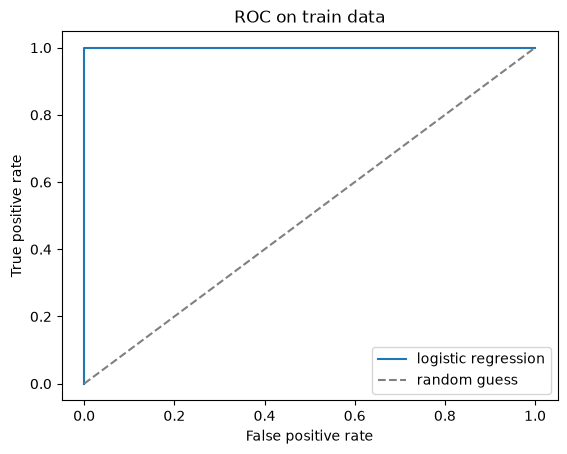

In [10]:
train_prob = final_model.predict_proba(X_train_best[:, selected_cols])[:, 1]
train_pred = final_model.predict(X_train_best[:, selected_cols])

print("Confusion matrix on train data (rows = true, columns = predicted; 0 = other, 1 = bending):")
print(confusion_matrix(y_train, train_pred))

fpr, tpr, _ = roc_curve(y_train, train_prob)
print("Train AUC:", roc_auc_score(y_train, train_prob))
plt.plot(fpr, tpr, label="logistic regression")
plt.plot([0, 1], [0, 1], "--", color="gray", label="random guess")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC on train data")
plt.legend()
plt.show()

In [11]:
# Coefficients (betas) and p-values. statsmodels gives a z-test p-value for each coefficient.
X_sm = sm.add_constant(X_train_best[:, selected_cols])
try:
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        sm_model = sm.Logit(y_train, X_sm).fit(disp=0, maxiter=100)
    if any("separation" in str(w.message) for w in caught):
        print("statsmodels warning: perfect separation detected, so these p-values are not reliable.\n")
    coef_table = pd.DataFrame({
        "sklearn beta": np.r_[final_model.intercept_, final_model.coef_[0]],
        "statsmodels beta": sm_model.params,
        "std error": sm_model.bse,
        "p-value": sm_model.pvalues,
    }, index=["intercept"] + selected_names)
    print(coef_table)
except Exception as e:
    print("statsmodels could not fit the model:", type(e).__name__, e)
    print(pd.DataFrame({"sklearn beta": np.r_[final_model.intercept_, final_model.coef_[0]]},
                       index=["intercept"] + selected_names))

statsmodels warning: perfect separation detected, so these p-values are not reliable.

            sklearn beta  statsmodels beta      std error   p-value
intercept     -10.304878        -31.529482  106198.360095  0.999763
min1           -2.259826         -7.874715  155758.332642  0.999960
max1            1.563863          8.689483  221324.386104  0.999969
3rd_quart1     -3.513277        -13.721078  279799.263834  0.999961
max2           -1.947357        -10.786844  205844.361749  0.999958
3rd_quart3     -1.445773         -1.142793  180897.804159  0.999995
max4            2.328499          9.052343  190665.694362  0.999962
1st_quart4     -1.994738         -8.474527  533188.577225  0.999987
min5            4.775560         21.021813  241787.783205  0.999931
max5            4.539330         10.635913  281026.766629  0.999970
mean5           2.955196          0.284933  391784.926201  0.999999
std6           -1.381974         -5.355050  410712.110948  0.999990
1st_quart6     -2.295295     

**Results on the training data:** the confusion matrix has no mistakes (all 60 "other" and all 9 bending are correct), and the AUC is 1.0.

**Betas and p-values:** the "sklearn beta" column is the model I actually use (stopped at max_iter = 100, with standardized features). statsmodels gives a warning about *perfect separation*. Its betas are different from sklearn's, its standard errors are huge (around $10^5$ or more), and so every p-value is about 1.0.

At first this looks strange. A large p-value usually means there is not enough evidence that the coefficient is different from 0, but this model gets every training instance right. The reason is that the two classes are perfectly separated, so the maximum likelihood estimate doesn't exist: the betas want to go to infinity. Because of this, the z-test doesn't work here, and these p-values can't be trusted. This is also why I used RFE instead of p-values to choose the features.

#### v. Test Classifier

In [12]:
test_pred = final_model.predict(X_test_best[:, selected_cols])
test_acc = accuracy_score(y_test, test_pred)
print("Confusion matrix on test data:")
print(confusion_matrix(y_test, test_pred))
print("Test accuracy:", round(test_acc, 4))
print("CV accuracy:  ", round(best_cv_acc, 4))

Confusion matrix on test data:
[[15  0]
 [ 0  4]]
Test accuracy: 1.0
CV accuracy:   0.9855


I make the test features the same way as the training features: I cut the test time series into the same number of parts (l = 1, so no cutting), keep the same 12 features, and use the scaler from the training set.

The test accuracy is **1.0** (all 19 test instances are correct), and the CV accuracy was **0.9855**. These two are very close. The test set is small (19 instances, and only 4 are bending), so just one mistake would change the test accuracy by about 5%. So I don't think the small difference means much.

#### vi. Separation

**Yes.** With the 12 chosen features, the two classes are perfectly separated in the training data: the training confusion matrix has no mistakes and the training AUC is 1.0. statsmodels also says "perfect separation", and it gives standard errors around $10^5$ and p-values near 1.

When the classes are well separated, the logistic regression estimates are unstable: the likelihood keeps getting better as the betas get bigger, so the betas go toward infinity. I can see this in my results: sklearn and statsmodels give quite different betas for the same features, just because they stopped at different points. So the classifier performs well on the data we have, but its coefficient estimates and p-values are unreliable.

#### vii. Imbalance

Yes, the classes are imbalanced. The confusion matrices show 9 bending vs. 60 other in the training set (only 13% bending), and 4 vs. 15 in the test set.

So I built a model with case-control sampling and then fixed its intercept. My steps:
1. Keep all 9 bending instances (the "cases") and randomly pick 9 "other" instances (the "controls"), so the sample is 50/50. I fixed the random seed so the result is the same every time.
2. Fit logistic regression on this sample, with the same 12 features as before.
3. The intercept is wrong, because bending is $\tilde\pi = 0.5$ of the sample but only $\pi = 9/69$ of the real data. The usual case-control adjustment only changes the intercept. (The slopes may still be unstable here, because the sample is small and the classes are separable.) I fix the intercept with this formula:
$$\hat\beta_0^* = \hat\beta_0 + \log\frac{\pi}{1-\pi} - \log\frac{\tilde\pi}{1-\tilde\pi}.$$
4. Report the confusion matrix, ROC and AUC on the full training set and on the test set. (I don't resample the test set, so it keeps the real imbalance.)

One thing I noticed: changing the intercept moves every score up or down by the same amount. So the order of the instances doesn't change, and the ROC curve and AUC stay the same. It only changes which side of the 0.5 cut-off a point is on, so it can change the confusion matrix.

pi = 0.1304  pi~ = 0.5
Intercept before: -5.7709  after adjustment: -7.668
Slopes: [-0.0761 -0.9555 -1.7734  0.2914 -0.9015  0.5752 -0.972   3.5021  4.8971
  1.5402 -1.6272 -2.7985]

Confusion matrix (train):
[[60  0]
 [ 0  9]]
AUC (train): 0.9999999999999999

Confusion matrix (test):
[[15  0]
 [ 0  4]]
AUC (test): 1.0


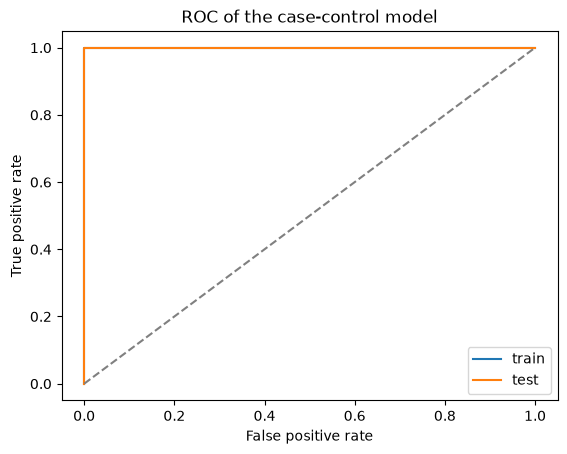

In [13]:
# Case-control sampling: keep all bending cases, randomly pick the same number of "other" controls.
rng = np.random.default_rng(0)
case_idx = np.where(y_train == 1)[0]
control_idx = rng.choice(np.where(y_train == 0)[0], size=len(case_idx), replace=False)
cc_idx = np.r_[case_idx, control_idx]

cc_model = plain_logistic().fit(X_train_best[cc_idx][:, selected_cols], y_train[cc_idx])

# Adjust the intercept: beta0* = beta0 + log(pi/(1-pi)) - log(pi~/(1-pi~))
pi_true = y_train.mean()          # share of bending in the full training set
pi_sample = y_train[cc_idx].mean()  # share of bending in the case-control sample (0.5)
old_b0 = cc_model.intercept_[0]
cc_model.intercept_[0] = old_b0 + np.log(pi_true / (1 - pi_true)) - np.log(pi_sample / (1 - pi_sample))
print("pi =", round(pi_true, 4), " pi~ =", pi_sample)
print("Intercept before:", round(old_b0, 4), " after adjustment:", round(cc_model.intercept_[0], 4))
print("Slopes:", np.round(cc_model.coef_[0], 4))

for name, X_part, y_part in [("train", X_train_best, y_train), ("test", X_test_best, y_test)]:
    prob = cc_model.predict_proba(X_part[:, selected_cols])[:, 1]
    pred = cc_model.predict(X_part[:, selected_cols])
    print(f"\nConfusion matrix ({name}):")
    print(confusion_matrix(y_part, pred))
    print(f"AUC ({name}):", roc_auc_score(y_part, prob))
    fpr, tpr, _ = roc_curve(y_part, prob)
    plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC of the case-control model")
plt.legend()
plt.show()

**Results of the case-control model:** after the fix, the intercept went from -5.77 to -7.67. The confusion matrices have no mistakes on the full training set (60/60 and 9/9) or on the test set (15/15 and 4/4), and the AUC is 1.0 on both. (The train AUC prints as 0.9999999999999999 just because of a tiny rounding error in the computer.) So with these features, the imbalance doesn't hurt the results, because the classes are separated anyway. But this model was trained on only 18 instances, so its coefficients are less certain than the full model's.

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

Here I use an L1 penalty instead of RFE, and choose how strong the penalty is with cross-validation. In sklearn, the strength is set by the budget C = 1/λ. A small C means a strong penalty, so more coefficients become exactly 0.

I use the liblinear solver and standardized features (the penalty treats all coefficients the same, so the features should be on the same scale). I try l = 1 to 20 and C from 0.01 to 100. Like before, I fit the scaler inside each fold (the right way), and I use the same stratified folds as in 2(a)iii so the two methods are compared fairly. If there is a tie, I pick the smaller l, then the smaller C (a stronger penalty, so a simpler model).

In [14]:
C_VALUES =[0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100]

l1_rows = []
for l in range(1, 21):
    X = extract_features(train_data, l).values
    correct = np.zeros(len(C_VALUES))
    for train_idx, val_idx in binary_folds:
        scaler = StandardScaler().fit(X[train_idx])
        X_tr = scaler.transform(X[train_idx])
        X_val = scaler.transform(X[val_idx])
        for j, C in enumerate(C_VALUES):
            model = LogisticRegression(penalty="l1", solver="liblinear", C=C, random_state=0)
            model.fit(X_tr, y_train[train_idx])
            correct[j] += np.sum(model.predict(X_val) == y_train[val_idx])
    for j, C in enumerate(C_VALUES):
        l1_rows.append({"l": l, "C": C, "cv_accuracy": correct[j] / len(y_train)})

l1_results = pd.DataFrame(l1_rows)
# Ties: smaller l first, then smaller C (stronger penalty = simpler model)
l1_results = l1_results.sort_values(["cv_accuracy", "l", "C"], ascending=[False, True, True])
print(l1_results.head(10).to_string(index=False))

l1_best_l = int(l1_results.iloc[0]["l"])
l1_best_C = float(l1_results.iloc[0]["C"])
l1_best_cv = l1_results.iloc[0]["cv_accuracy"]
print("\nBest (l, C) =", (l1_best_l, l1_best_C), " CV accuracy =", round(l1_best_cv, 4))

 l     C  cv_accuracy
 1   1.0     0.985507
 1   3.0     0.985507
 1  10.0     0.985507
20  10.0     0.985507
 1   0.3     0.971014
 1  30.0     0.971014
 1 100.0     0.971014
 2  30.0     0.971014
 2 100.0     0.971014
 3   0.3     0.971014

Best (l, C) = (1, 1.0)  CV accuracy = 0.9855


In [15]:
train_l1b = extract_features(train_data, l1_best_l)
test_l1b = extract_features(test_data, l1_best_l)
scaler_l1 = StandardScaler().fit(train_l1b.values)
X_train_l1 = scaler_l1.transform(train_l1b.values)
X_test_l1 = scaler_l1.transform(test_l1b.values)

l1_model = LogisticRegression(penalty="l1", solver="liblinear", C=l1_best_C, random_state=0)
l1_model.fit(X_train_l1, y_train)
nonzero = np.where(l1_model.coef_[0] != 0)[0]
print("Number of non-zero coefficients:", len(nonzero), "out of", X_train_l1.shape[1])
print(pd.Series(l1_model.coef_[0][nonzero], index=train_l1b.columns[nonzero]))

print("\nTrain confusion matrix:")
print(confusion_matrix(y_train, l1_model.predict(X_train_l1)))
print("Test confusion matrix:")
print(confusion_matrix(y_test, l1_model.predict(X_test_l1)))
l1_test_acc = accuracy_score(y_test, l1_model.predict(X_test_l1))
print("Test accuracy:", round(l1_test_acc, 4), "  CV accuracy:", round(l1_best_cv, 4))

Number of non-zero coefficients: 7 out of 42
3rd_quart1   -0.568702
1st_quart3   -0.019295
1st_quart4   -0.122210
min5          1.101264
max5          1.738362
median6      -0.206029
1st_quart6   -0.589794
dtype: float64

Train confusion matrix:
[[60  0]
 [ 0  9]]
Test confusion matrix:
[[15  0]
 [ 0  4]]
Test accuracy: 1.0   CV accuracy: 0.9855


The best pair is **(l, C) = (1, 1.0)**, with CV accuracy 0.9855 (the same as in 2(a)iii). Again, l = 1 is enough. The L1 penalty made 35 of the 42 coefficients exactly 0, so the model only keeps **7 features**. It makes no mistakes on the training set or on the 19 test instances (test accuracy 1.0).

#### ii. Comparison

| | RFE selection (2(a)iii) | L1-penalized (2(b)i) |
|---|---|---|
| best l | 1 | 1 |
| features used | 12 | 7 |
| CV accuracy | 0.9855 | 0.9855 |
| test accuracy | 1.0 | 1.0 |

**Which one performs better?** For accuracy, they tie: the same CV accuracy, and both are perfect on the test set. But I think L1 is a little better overall, because it gets the same accuracy with fewer features (7 vs. 12). Also, the penalty keeps its coefficients from blowing up, even though the classes are separable. The model without a penalty has coefficients that go toward infinity (see 2(a)vi).

**Which one is easier to implement?** L1. It chooses the features and fits the model in one step: I tune l and C, without a separate RFE step. The RFE way needs a separate selection step that has to be repeated inside every fold, plus I have to choose p. Selecting features by p-values would also not work here, because perfect separation makes the p-values unreliable.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

Now I classify all 7 activities: bending1, bending2, cycling, lying, sitting, standing and walking. I use multinomial (multiclass) logistic regression with an L1 penalty.

The liblinear solver can only do one-vs-rest, not a real multinomial model, so I use the saga solver, which can fit a multinomial model with an L1 penalty. The search is the same as in 2(b)i: l = 1 to 20, a grid of C values, 5 stratified folds, and the scaler fit inside each fold. bending2 only has 4 training instances, so with 5 folds one fold can't get a bending2 instance (sklearn prints a warning about this). I still use 5 folds because the homework asks for 5-fold CV.

**Confusion matrix and ROC for more than 2 classes** (the homework asks us to look this up):
- The confusion matrix becomes a 7 × 7 table. Each row is the true activity, and each column is the predicted activity. The numbers on the diagonal are the correct ones.
- An ROC curve is made for 2 classes, so for many classes I use **one-vs-rest**: for each activity, I treat that activity as "positive" and all the other activities as "negative", and use the predicted probability of that activity as the score. This gives one ROC curve and one AUC for each class. The macro-average AUC is just the average of the 7 AUCs.

In [16]:
y_train_multi = train_activity
y_test_multi = test_activity
# bending2 has only 4 training instances, so one of the 5 folds has no bending2 (sklearn warns about this).
multi_folds = list(skf.split(np.zeros(len(y_train_multi)), y_train_multi))

# saga is slow, so we use a smaller grid of C here (this cell takes several minutes).
C_VALUES_MULTI = [0.01, 0.1, 1, 10, 100]


def l1_multinomial(C):
    # liblinear cannot fit a multinomial model; saga can, with an L1 penalty.
    # max_iter=5000; the search below counts how many fits still hit this limit.
    # saga shuffles the data, so we fix random_state to get the same result every run.
    return LogisticRegression(penalty="l1", solver="saga", C=C, max_iter=5000, random_state=0)


multi_rows = []
not_converged = 0
for l in range(1, 21):
    X = extract_features(train_data, l).values
    correct = np.zeros(len(C_VALUES_MULTI))
    for train_idx, val_idx in multi_folds:
        scaler = StandardScaler().fit(X[train_idx])
        X_tr = scaler.transform(X[train_idx])
        X_val = scaler.transform(X[val_idx])
        for j, C in enumerate(C_VALUES_MULTI):
            model = l1_multinomial(C).fit(X_tr, y_train_multi[train_idx])
            correct[j] += np.sum(model.predict(X_val) == y_train_multi[val_idx])
            if model.n_iter_[0] >= 5000:
                not_converged += 1
    for j, C in enumerate(C_VALUES_MULTI):
        multi_rows.append({"l": l, "C": C, "cv_accuracy": correct[j] / len(y_train_multi)})

print("Fits that hit max_iter without converging:", not_converged, "out of", 20 * 5 * len(C_VALUES_MULTI))
multi_results = pd.DataFrame(multi_rows)
multi_results = multi_results.sort_values(["cv_accuracy", "l", "C"], ascending=[False, True, True])
print(multi_results.head(10).to_string(index=False))

multi_best_l = int(multi_results.iloc[0]["l"])
multi_best_C = float(multi_results.iloc[0]["C"])
print("\nBest (l, C) =", (multi_best_l, multi_best_C),
      " CV accuracy =", round(multi_results.iloc[0]["cv_accuracy"], 4))

C:\Users\wayne\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


Fits that hit max_iter without converging: 22 out of 500
 l     C  cv_accuracy
 1  10.0     0.927536
 1   1.0     0.884058
 1 100.0     0.884058
 2   1.0     0.869565
 2 100.0     0.855072
 3  10.0     0.855072
 6  10.0     0.855072
 6 100.0     0.855072
 2  10.0     0.840580
 4 100.0     0.840580

Best (l, C) = (1, 10.0)  CV accuracy = 0.9275


saga iterations used: [2451] (max 5000)
Test error: 0.0526


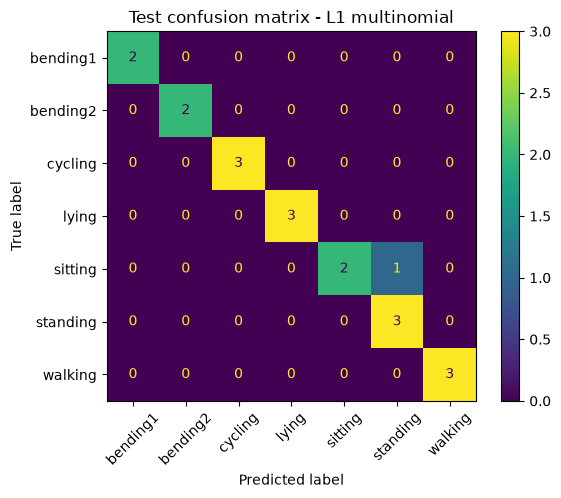

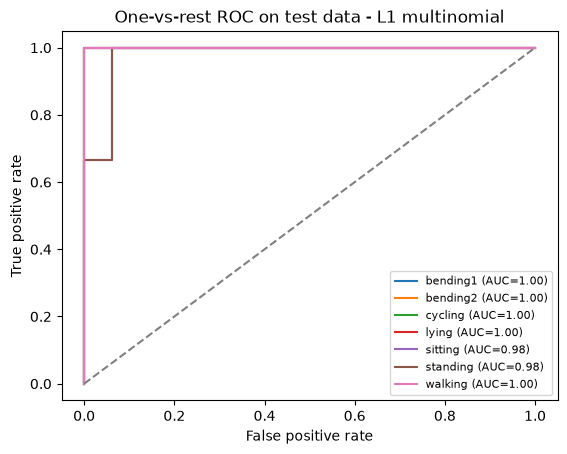

Macro-average one-vs-rest AUC: 0.994


In [17]:
def show_multiclass_results(model, X_tr, X_te, title):
    pred = model.predict(X_te)
    print("Test error:", round(1 - accuracy_score(y_test_multi, pred), 4))

    # Confusion matrix: rows = true activity, columns = predicted activity
    cm = confusion_matrix(y_test_multi, pred, labels=activities)
    ConfusionMatrixDisplay(cm, display_labels=activities).plot(xticks_rotation=45)
    plt.title("Test confusion matrix - " + title)
    plt.show()

    # One-vs-rest ROC: one curve per activity ("this activity" vs "all others")
    prob = model.predict_proba(X_te)
    y_bin = label_binarize(y_test_multi, classes=model.classes_)
    for k, activity in enumerate(model.classes_):
        fpr, tpr, _ = roc_curve(y_bin[:, k], prob[:, k])
        auc_k = roc_auc_score(y_bin[:, k], prob[:, k])
        plt.plot(fpr, tpr, label=f"{activity} (AUC={auc_k:.2f})")
    plt.plot([0, 1], [0, 1], "--", color="gray")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title("One-vs-rest ROC on test data - " + title)
    plt.legend(fontsize=8)
    plt.show()
    print("Macro-average one-vs-rest AUC:",
          round(roc_auc_score(y_test_multi, prob, multi_class="ovr", labels=model.classes_), 4))


train_m = extract_features(train_data, multi_best_l)
test_m = extract_features(test_data, multi_best_l)
scaler_m = StandardScaler().fit(train_m.values)
X_train_m = scaler_m.transform(train_m.values)
X_test_m = scaler_m.transform(test_m.values)

multi_model = l1_multinomial(multi_best_C).fit(X_train_m, y_train_multi)
print("saga iterations used:", multi_model.n_iter_, "(max 5000)")
show_multiclass_results(multi_model, X_train_m, X_test_m, "L1 multinomial")

The best pair is **(l, C) = (1, 10)**, with CV accuracy 0.9275. During the search, 22 of the 500 saga fits used all 5000 iterations without fully converging (my code counts them). Some candidate fits did not converge, so their CV scores may be affected by the iteration limit. The final model did converge (it needed 2451 iterations).

**Test error = 0.0526** (1 of the 19 test instances is wrong). The confusion matrix shows the one mistake: a *sitting* instance was predicted as *standing*. The one-vs-rest ROC curves are close to the top-left corner, and the macro-average AUC is 0.994.

#### ii. Naive Bayes

Naive Bayes assumes that the features are independent inside each class, so $f_k(x) = f_{k1}(x_1)\cdots f_{kp}(x_p)$. Then it uses Bayes theorem to pick the class.
- **Gaussian NB** describes each feature in each class with a normal (bell) curve.
- **Multinomial NB** treats the features like counts (it is usually used for counting words in text). It needs all features to be $\ge 0$. All my raw features are $\ge 0$, so I use them as they are. If I standardized them, some would become negative, so I don't standardize here.

Naive Bayes has no penalty to tune, so I only choose l, using the same 5 stratified folds. If two values of l tie, I pick the smaller one.

In [18]:
# Naive Bayes uses the raw features (no scaling). MultinomialNB needs features >= 0,
# and all extracted features in this dataset are >= 0.
nb_rows = []
for l in range(1, 21):
    X = extract_features(train_data, l).values
    correct_gauss, correct_multi = 0, 0
    for train_idx, val_idx in multi_folds:
        g = GaussianNB().fit(X[train_idx], y_train_multi[train_idx])
        m = MultinomialNB().fit(X[train_idx], y_train_multi[train_idx])
        correct_gauss += np.sum(g.predict(X[val_idx]) == y_train_multi[val_idx])
        correct_multi += np.sum(m.predict(X[val_idx]) == y_train_multi[val_idx])
    nb_rows.append({"l": l,
                    "gaussian_cv_accuracy": correct_gauss / len(y_train_multi),
                    "multinomial_cv_accuracy": correct_multi / len(y_train_multi)})

nb_results = pd.DataFrame(nb_rows)
print(nb_results.to_string(index=False))

# idxmax returns the first (smallest) l when there is a tie
gauss_best_l = int(nb_results.loc[nb_results["gaussian_cv_accuracy"].idxmax(), "l"])
mnb_best_l = int(nb_results.loc[nb_results["multinomial_cv_accuracy"].idxmax(), "l"])
print("\nBest l for Gaussian NB:", gauss_best_l)
print("Best l for Multinomial NB:", mnb_best_l)

 l  gaussian_cv_accuracy  multinomial_cv_accuracy
 1              0.855072                 0.855072
 2              0.768116                 0.768116
 3              0.681159                 0.782609
 4              0.652174                 0.739130
 5              0.681159                 0.782609
 6              0.637681                 0.768116
 7              0.579710                 0.811594
 8              0.608696                 0.768116
 9              0.565217                 0.797101
10              0.666667                 0.739130
11              0.608696                 0.753623
12              0.608696                 0.753623
13              0.608696                 0.768116
14              0.550725                 0.753623
15              0.579710                 0.782609
16              0.536232                 0.753623
17              0.550725                 0.782609
18              0.507246                 0.753623
19              0.550725                 0.768116


For both naive Bayes models, the best value is **l = 1** (CV accuracy 0.855 for both). Gaussian NB gets worse quickly as l gets bigger: its CV accuracy goes from 0.855 at l = 1 down to about 0.54 at l = 20. I think this may be because more pieces means many more features that are strongly related to each other (which goes against the "independent features" assumption), while each class still has very few training instances.

Test error: 0.1053


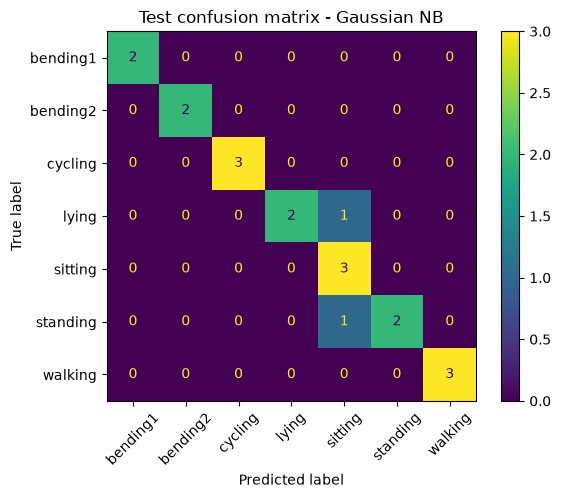

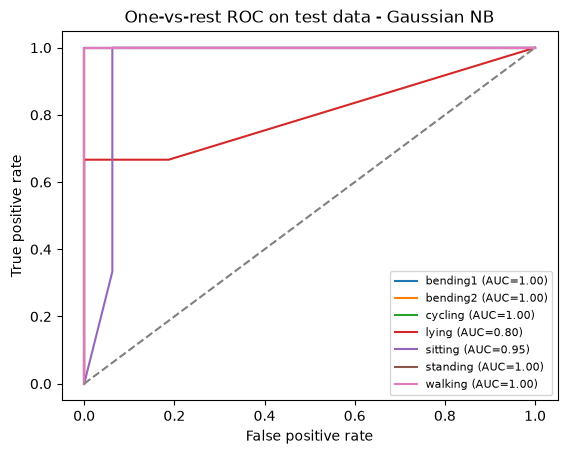

Macro-average one-vs-rest AUC: 0.9643


In [19]:
X_train_g = extract_features(train_data, gauss_best_l).values
X_test_g = extract_features(test_data, gauss_best_l).values
gauss_model = GaussianNB().fit(X_train_g, y_train_multi)
show_multiclass_results(gauss_model, X_train_g, X_test_g, "Gaussian NB")

Test error: 0.1053


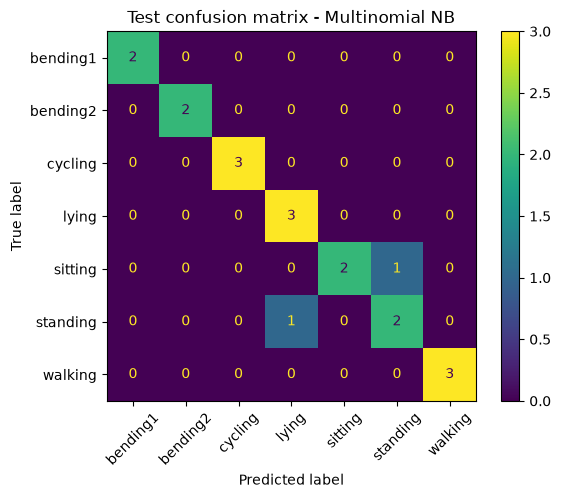

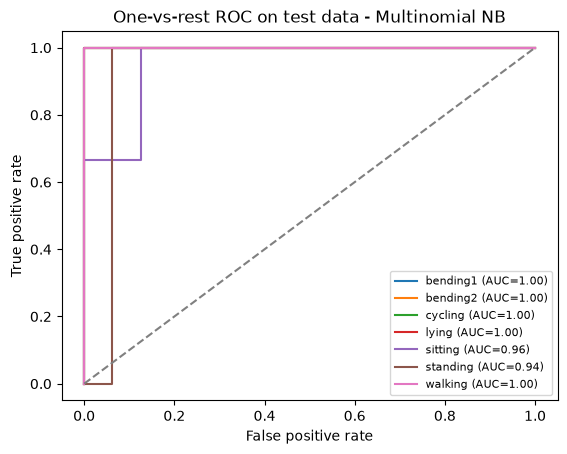

Macro-average one-vs-rest AUC: 0.9851


In [20]:
X_train_mn = extract_features(train_data, mnb_best_l).values
X_test_mn = extract_features(test_data, mnb_best_l).values
mnb_model = MultinomialNB().fit(X_train_mn, y_train_multi)
show_multiclass_results(mnb_model, X_train_mn, X_test_mn, "Multinomial NB")

**Gaussian vs. Multinomial NB:**

| | Gaussian NB | Multinomial NB |
|---|---|---|
| best l | 1 | 1 |
| CV accuracy | 0.855 | 0.855 |
| test error | 0.1053 (2 of 19 wrong) | 0.1053 (2 of 19 wrong) |
| macro AUC (test) | 0.964 | 0.985 |

Both models make 2 mistakes on the test set, and all the mistakes are among the "still" activities (lying, sitting and standing):
- Gaussian NB calls one lying instance and one standing instance "sitting".
- Multinomial NB calls one sitting instance "standing" and one standing instance "lying".

Their test errors are the same. Multinomial NB has a higher AUC, so its probabilities rank the instances a bit better. Its CV accuracy is also higher than Gaussian NB's for every l from 3 to 20.

#### iii. Comparison

| | L1 multinomial logistic regression | Gaussian NB | Multinomial NB |
|---|---|---|---|
| best l | 1 | 1 | 1 |
| CV accuracy | 0.928 | 0.855 | 0.855 |
| test error | **0.053** | 0.105 | 0.105 |
| macro AUC (test) | **0.994** | 0.964 | 0.985 |

**I think L1-penalized multinomial logistic regression is the best method here.** It has the highest CV accuracy, the lowest test error (1 mistake vs. 2) and the highest AUC.

Why? My guess is that the features are strongly related to each other (for example, the mean, the median and the quartiles of the same series go up and down together), but naive Bayes assumes they are independent inside each class. Logistic regression doesn't need that assumption, and the L1 penalty also removes extra features. Naive Bayes is simpler and much faster, though.

There are only 19 test instances, so the difference is just 1 instance. That's why I trust the CV accuracy more for comparing, and it points the same way. Also, as I found in Part 1, some cycling and lying test files have exact copies in the training set, so the test results for these classes are probably a bit too good for every method.

## 3. ISLR 4.8.3

**Problem:** There is only one feature $X$ ($p=1$). In class $k$, $X \sim N(\mu_k, \sigma_k^2)$, so each class has its **own** variance. Prove that the Bayes classifier is not linear in $x$; it is quadratic.

**My answer:**

The Bayes classifier puts $x$ in the class with the biggest

$$p_k(x) = \frac{\pi_k f_k(x)}{\sum_{l=1}^K \pi_l f_l(x)}, \qquad f_k(x) = \frac{1}{\sqrt{2\pi}\,\sigma_k}\exp\!\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right).$$

The bottom of the fraction is the same for every class, so I only need to find the class with the biggest $\pi_k f_k(x)$. The log function always goes up, so comparing $\log(\pi_k f_k(x))$ gives the same answer:

$$\log(\pi_k f_k(x)) = \log \pi_k - \log\sqrt{2\pi} - \log \sigma_k - \frac{(x-\mu_k)^2}{2\sigma_k^2}.$$

$-\log\sqrt{2\pi}$ is the same for every class, so I can drop it. Then I expand $(x-\mu_k)^2 = x^2 - 2x\mu_k + \mu_k^2$:

$$\delta_k(x) = -\frac{x^2}{2\sigma_k^2} + \frac{\mu_k}{\sigma_k^2}\,x - \frac{\mu_k^2}{2\sigma_k^2} - \log \sigma_k + \log \pi_k .$$

The Bayes classifier picks the class with the biggest $\delta_k(x)$.

If all the classes had the same variance ($\sigma_k = \sigma$, like in LDA), the $x^2$ term $-x^2/(2\sigma^2)$ would be the same for every class. It would cancel when we compare two classes, and $\delta_k(x)$ would be linear in $x$.

But here each class has its own $\sigma_k$, so the $x^2$ term has a different number in front of it ($-1/(2\sigma_k^2)$) in each class, and it does **not** cancel. For example, the border between class $k$ and class $l$ is where $\delta_k(x) = \delta_l(x)$:

$$\left(\frac{1}{2\sigma_l^2} - \frac{1}{2\sigma_k^2}\right)x^2 + \left(\frac{\mu_k}{\sigma_k^2} - \frac{\mu_l}{\sigma_l^2}\right)x + \text{(constant)} = 0,$$

and the number in front of $x^2$ is not 0 when $\sigma_k \ne \sigma_l$. So $\delta_k(x)$ is a quadratic function of $x$, which means the Bayes classifier is quadratic, not linear. $\blacksquare$

## 4. ISLR 4.8.7

**Problem:** We want to predict if a company will issue a dividend ("Yes" or "No") using $X$ = last year's percent profit. For companies that issued a dividend, the mean of $X$ is $\bar{X}=10$. For companies that did not, the mean is $\bar{X}=0$. The variance of $X$ is $\hat\sigma^2 = 36$ for both groups, and 80% of the companies issued dividends. Assume $X$ is normal in each group. What is the probability that a company with $X=4$ issues a dividend?

**My answer:**

I use Bayes theorem with a normal density in each group:
$$f_k(x) = \frac{1}{\sqrt{2\pi\cdot 36}}\exp\!\left(-\frac{(x-\mu_k)^2}{2\cdot 36}\right).$$
Both groups have the same variance, so the part $\frac{1}{\sqrt{2\pi\cdot 36}}$ is on both the top and the bottom, and it cancels:

$$P(\text{Yes}\mid X=4) = \frac{0.8\, e^{-(4-10)^2/72}}{0.8\, e^{-(4-10)^2/72} + 0.2\, e^{-(4-0)^2/72}} = \frac{0.8\, e^{-0.5}}{0.8\, e^{-0.5} + 0.2\, e^{-2/9}}.$$

$0.8\,e^{-0.5} \approx 0.4852$ and $0.2\,e^{-2/9} \approx 0.1601$, so

$$P(\text{Yes}\mid X=4) \approx \frac{0.4852}{0.4852 + 0.1601} \approx 0.752.$$

So the probability is about **75.2%**. I also checked the numbers with a few lines of code below.

In [21]:
pi_yes, pi_no = 0.8, 0.2
var = 36
x = 4
top = pi_yes * np.exp(-(x - 10) ** 2 / (2 * var))
bottom = top + pi_no * np.exp(-(x - 0) ** 2 / (2 * var))
print("P(Yes | X = 4) =", round(top / bottom, 4))

P(Yes | X = 4) = 0.7519
